# Laboratorium 3 — Otwarte dane i wartości odstające

**Eksploracja danych** · dr Paweł Gliwny · WFiIS UŁ

Na tych zajęciach:

1. **Część 1** — pobierzesz dane z portalu otwartych danych Łodzi, wczytasz je, zmienisz ich format, policzysz statystyki zbiorcze i zrobisz proste wykresy.
2. **Część 2** — na danych o pacjentach przejdziesz kolejne kroki wykrywania wartości odstających: od najprostszych do bardziej złożonych.

Miejsca do uzupełnienia oznaczone są `# TODO`. Odpowiedzi na pytania wpisuj w komórkach tekstowych oznaczonych ✍️.

> Notatnik po zajęciach umieść w swoim repozytorium na GitHubie.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.dpi"] = 100

In [33]:
def upewnij_sie_ze_jest(nazwa_pliku):
    if Path(nazwa_pliku).exists():
        print(f"Plik {nazwa_pliku} jest na miejscu.")
        return
    try:
        from google.colab import files
        print(f"Wgraj plik {nazwa_pliku}:")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Umieść plik {nazwa_pliku} w folderze z notatnikiem.")

---
# Część 1. Dane z portalu otwartych danych Łodzi

Portal: [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl)

Zaczynamy od wspólnego przykładu — pliku `szkolnictwo_wysze.csv` (szkolnictwo wyższe w Łodzi w latach 2012–2024). Pobierz go z portalu albo od prowadzącego i wgraj do Colaba (ikona folderu po lewej lub komórka poniżej).

In [3]:
PLIK_LODZ = "szkolnictwo_wysze.csv"
upewnij_sie_ze_jest(PLIK_LODZ)

Plik szkolnictwo_wysze.csv jest na miejscu.


## 1.1 Wczytanie danych

Zanim wywołasz `read_csv`, obejrzyj surowy plik — pierwsze linie tekstu powiedzą, jaki jest separator.

In [32]:
with open(PLIK_LODZ, encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())

﻿name;rok;wartość;zmienna
Szkolnictwo wyższe;2012;22;uczelnie
Szkolnictwo wyższe;2013;22;uczelnie
Szkolnictwo wyższe;2014;23;uczelnie
Szkolnictwo wyższe;2015;21;uczelnie


In [5]:
df = pd.read_csv(PLIK_LODZ, sep=";", encoding="utf-8")

display(df.head())
print("Wymiary:", df.shape)
print(df.dtypes)

,name,rok,wartość,zmienna
0,Szkolnictwo wyższe,2012,22,uczelnie
1,Szkolnictwo wyższe,2013,22,uczelnie
2,Szkolnictwo wyższe,2014,23,uczelnie
3,Szkolnictwo wyższe,2015,21,uczelnie
4,Szkolnictwo wyższe,2016,20,uczelnie


Wymiary: (65, 4)
name       object
rok         int64
wartość     int64
zmienna    object
dtype: object


✍️ **Pytanie:** Jaki jest separator? Czy kolumna `wartość` ma typ liczbowy? Czy nazwy kolumn z polskimi znakami wczytały się poprawnie?

*Odpowiedź:* Separatorem jest ';', kolumna wartość ma int64, tak ponieważ plik jest w kodowaniu utf-8

## 1.2 Format długi czy szeroki?

Przypomnienie z wykładu 2: w formacie **długim** każdy wiersz to jedna para (zmienna, wartość); w formacie **szerokim** każda zmienna ma własną kolumnę.

1. Sprawdź, jakie wartości przyjmuje kolumna `zmienna` i ile razy każda występuje.
2. Przekształć dane do formatu szerokiego: wiersze = lata, kolumny = zmienne.

In [6]:
print(df["zmienna"].value_counts())

szeroka = df.pivot(index="rok", columns="zmienna", values="wartość")
szeroka.columns.name = None
szeroka

zmienna
uczelnie             13
ogółem               13
kobiety              13
mężczyźni            13
absolwenci ogółem    13
Name: count, dtype: int64


,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie
rok,,,,,
2012,24825,55265,36281,91546,22
2013,22590,50007,33464,83471,22
2014,21343,48220,32456,80676,23
2015,19835,45584,30769,76353,21
2016,17662,44053,29908,73961,20
2017,19281,42990,29029,72019,22
2018,17046,39312,26253,65565,20
2019,15819,38146,26297,64443,19
2020,14082,39170,26155,65325,18


## 1.3 Czy dane są spójne?

Liczba studentów `ogółem` powinna być sumą `kobiety` i `mężczyźni`. Sprawdź to dla każdego roku.

In [7]:
roznica = szeroka["kobiety"] + szeroka["mężczyźni"] - szeroka["ogółem"]
display(roznica.to_frame("(kobiety + mężczyźni) − ogółem"))
print("Wszystkie lata spójne:", (roznica == 0).all())

,(kobiety + mężczyźni) − ogółem
rok,
2012,0
2013,0
2014,0
2015,0
2016,0
2017,0
2018,0
2019,0
2020,0


Wszystkie lata spójne: True


## 1.4 Statystyki zbiorcze

1. Policz statystyki opisowe dla wszystkich zmiennych (`describe`).
2. O ile procent zmieniła się każda zmienna między 2012 a 2024 rokiem?
3. Dodaj kolumnę `udzial_kobiet` (udział kobiet wśród studentów) i kolumnę `studenci_na_uczelnie`.

In [8]:
display(szeroka.describe().T)

zmiana = (szeroka.loc[2024] / szeroka.loc[2012] - 1) * 100
display(zmiana.round(1).to_frame("zmiana 2012→2024 [%]"))

szeroka["udzial_kobiet"] = szeroka["kobiety"] / szeroka["ogółem"]
szeroka["studenci_na_uczelnie"] = szeroka["ogółem"] / szeroka["uczelnie"]
szeroka[["udzial_kobiet", "studenci_na_uczelnie"]]

,count,mean,std,min,25%,50%,75%,max
absolwenci ogółem,13.00,17780.54,3522.40,14082.00,14756.00,17046.00,19835.00,24825.00
kobiety,13.00,43010.92,5391.05,38146.00,39170.00,39958.00,45584.00,55265.00
mężczyźni,13.00,28793.92,3524.63,25710.00,26049.00,26297.00,30769.00,36281.00
ogółem,13.00,71804.85,8900.65,64272.00,65297.00,66002.00,76353.00,91546.00
uczelnie,13.00,19.54,2.44,15.00,18.00,20.00,22.00,23.00


,zmiana 2012→2024 [%]
absolwenci ogółem,-41.30
kobiety,-30.20
mężczyźni,-29.10
ogółem,-29.80
uczelnie,-31.80


,udzial_kobiet,studenci_na_uczelnie
rok,,
2012,0.60,4161.18
2013,0.60,3794.14
2014,0.60,3507.65
2015,0.60,3635.86
2016,0.60,3698.05
2017,0.60,3273.59
2018,0.60,3278.25
2019,0.59,3391.74
2020,0.60,3629.17


## 1.5 Wykresy

Narysuj trzy wykresy (najlepiej obok siebie, `plt.subplots(1, 3)`):

1. liczba studentów w czasie — osobne linie dla kobiet i mężczyzn,
2. liczba uczelni w czasie,
3. udział kobiet wśród studentów (oś Y od 0 do 1).

Każdy wykres podpisz: tytuł, opisy osi.

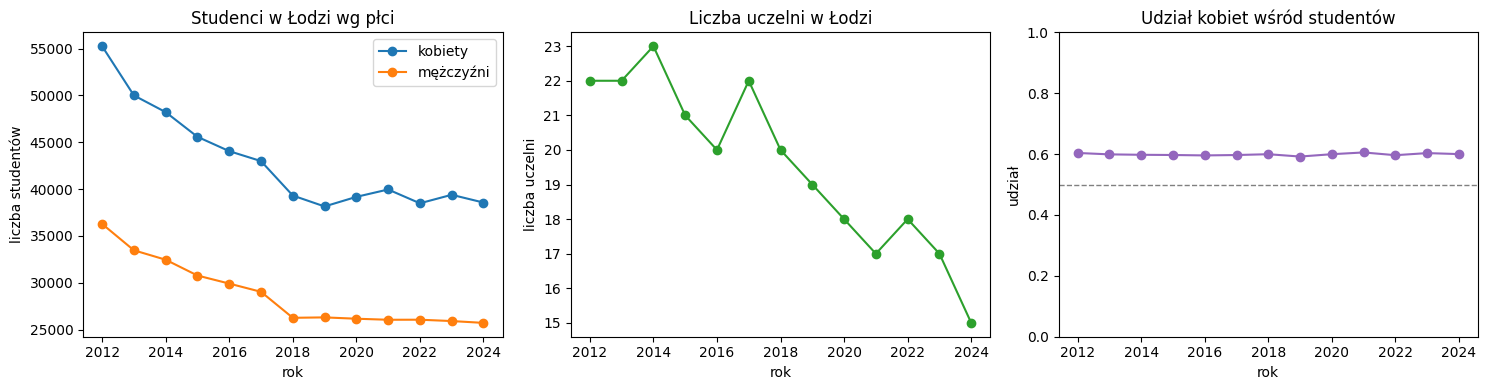

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
lata = szeroka.index

axes[0].plot(lata, szeroka["kobiety"], marker="o", label="kobiety")
axes[0].plot(lata, szeroka["mężczyźni"], marker="o", label="mężczyźni")
axes[0].set(title="Studenci w Łodzi wg płci", xlabel="rok", ylabel="liczba studentów")
axes[0].legend()

axes[1].plot(lata, szeroka["uczelnie"], marker="o", color="tab:green")
axes[1].set(title="Liczba uczelni w Łodzi", xlabel="rok", ylabel="liczba uczelni")

axes[2].plot(lata, szeroka["udzial_kobiet"], marker="o", color="tab:purple")
axes[2].axhline(0.5, ls="--", color="gray", lw=1)
axes[2].set(title="Udział kobiet wśród studentów", xlabel="rok", ylabel="udział", ylim=(0, 1))

plt.tight_layout()
plt.show()

✍️ **Wnioski** (3 zdania): co się stało ze szkolnictwem wyższym w Łodzi w latach 2012–2024?

*Odpowiedź:* Liczba studentów w Łodzi spadła z 91,5 tys w 2012 r. do 64,3 tys w 2024 r. Cały spadek nastąpił w latach 2012-2018, natomias od 2019 liczba stabilizuje się. Liczba uczelni zmalała w podobnym tempie z 22 do 15, więc na jedną uczelnię przypada ok. 4 tys studentów.

## 1.6 Zadanie samodzielne: Twój zbiór z portalu Łodzi

Wybierz **inny** zbiór z [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl) i przejdź te same kroki:

1. Podaj nazwę zbioru, link i datę pobrania.
2. Wczytaj plik (separator? kodowanie? przecinek dziesiętny?).
3. Ustal, czy dane są w formacie długim, czy szerokim; w razie potrzeby przekształć.
4. Sprawdź braki (`isna().sum()`) i spójność danych.
5. Policz statystyki zbiorcze.
6. Zrób 2–3 podpisane wykresy i napisz 2–3 zdania wniosków.

✍️ **Zbiór:** … · **link:** … · **data pobrania:** …

1.
Ludność wg płci w Łodzi.csv
https://otwarte.miasto.lodz.pl/ludnosc/
22.10.2026

In [30]:
PLIK_WLASNY = "ludno-wg-pci-w-odzi.csv"

with open(PLIK_WLASNY, encoding="utf-8-sig") as f:
    for _ in range(5):
        print(f.readline().rstrip())

ludnosc = pd.read_csv(PLIK_WLASNY, sep=";", encoding="utf-8-sig", thousands=" ")

display(ludnosc.head())
print("Wymiary:", ludnosc.shape)
print(ludnosc.dtypes)
print("\nBraki:\n", ludnosc.isna().sum())
print("\nZmienne:\n", ludnosc["zmienne"].value_counts())
print("Duplikaty (rok, zmienne):", ludnosc.duplicated(["rok", "zmienne"]).sum())

name;rok;wartość;zmienne
Ludność wg płci;1995;823 215;ogółem
Ludność wg płci;1996;817 983;ogółem
Ludność wg płci;1997;812 317;ogółem
Ludność wg płci;1998;806 728;ogółem


,name,rok,wartość,zmienne
0,Ludność wg płci,1995,823215,ogółem
1,Ludność wg płci,1996,817983,ogółem
2,Ludność wg płci,1997,812317,ogółem
3,Ludność wg płci,1998,806728,ogółem
4,Ludność wg płci,1999,805311,ogółem


Wymiary: (93, 4)
name       object
rok         int64
wartość     int64
zmienne    object
dtype: object

Braki:
 name       0
rok        0
wartość    0
zmienne    0
dtype: int64

Zmienne:
 zmienne
ogółem       31
mężczyźni    31
kobiety      31
Name: count, dtype: int64
Duplikaty (rok, zmienne): 0


Wszystkie lata spójne: True


,count,mean,std,min,25%,50%,75%,max
kobiety,31.00,399031.77,30418.51,347561.00,374371.50,398266.00,424982.00,445712.00
mężczyźni,31.00,334632.68,26340.21,292329.00,313482.00,332367.00,357149.50,377503.00
ogółem,31.00,733664.45,56737.54,639890.00,687853.50,730633.00,782131.50,823215.00


,zmiana 1995→2025 [%]
kobiety,-22.00
mężczyźni,-22.60
ogółem,-22.30


Średni roczny ubytek: -6111 osób
Największy spadek: 2010 -11754


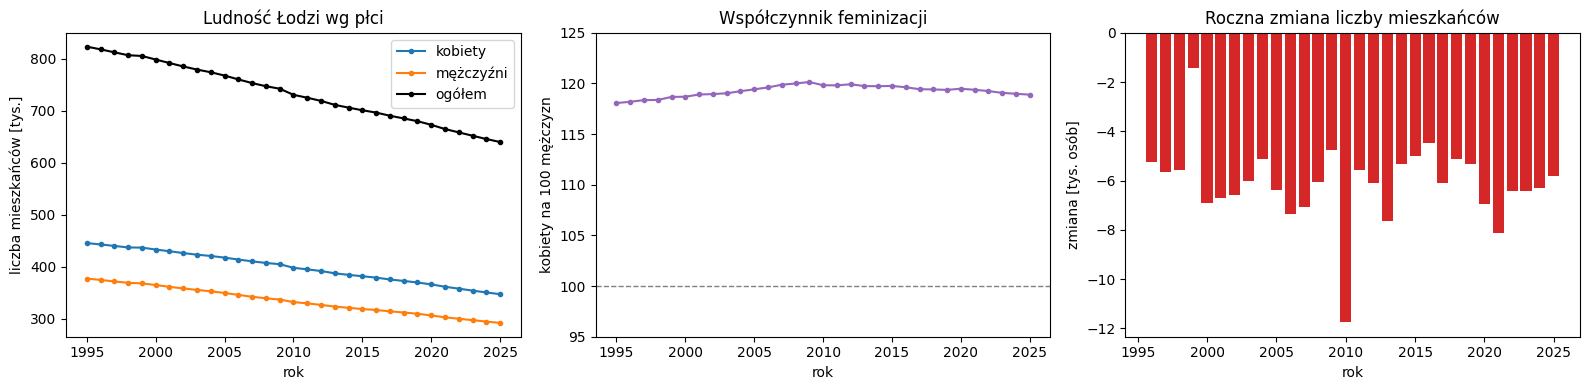

In [31]:
lud = ludnosc.pivot(index="rok", columns="zmienne", values="wartość").sort_index()
lud.columns.name = None

roznica = lud["kobiety"] + lud["mężczyźni"] - lud["ogółem"]
print("Wszystkie lata spójne:", (roznica == 0).all())

display(lud.describe().T)

zmiana = (lud.loc[2025] / lud.loc[1995] - 1) * 100
display(zmiana.round(1).to_frame("zmiana 1995→2025 [%]"))

lud["kobiety_na_100_mezczyzn"] = lud["kobiety"] / lud["mężczyźni"] * 100
lud["zmiana_roczna"] = lud["ogółem"].diff()
print("Średni roczny ubytek:", round(lud["zmiana_roczna"].mean()), "osób")
print("Największy spadek:", lud["zmiana_roczna"].idxmin(), int(lud["zmiana_roczna"].min()))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(lud.index, lud["kobiety"] / 1000, marker=".", label="kobiety")
axes[0].plot(lud.index, lud["mężczyźni"] / 1000, marker=".", label="mężczyźni")
axes[0].plot(lud.index, lud["ogółem"] / 1000, marker=".", label="ogółem", color="black")
axes[0].set(title="Ludność Łodzi wg płci", xlabel="rok", ylabel="liczba mieszkańców [tys.]")
axes[0].legend()

axes[1].plot(lud.index, lud["kobiety_na_100_mezczyzn"], marker=".", color="tab:purple")
axes[1].axhline(100, ls="--", color="gray", lw=1)
axes[1].set(title="Współczynnik feminizacji", xlabel="rok",
            ylabel="kobiety na 100 mężczyzn", ylim=(95, 125))

axes[2].bar(lud.index, lud["zmiana_roczna"] / 1000, color="tab:red")
axes[2].set(title="Roczna zmiana liczby mieszkańców", xlabel="rok", ylabel="zmiana [tys. osób]")

plt.tight_layout()
plt.show()

✍️ **Wnioski:** Dane są w formacie długim, bez braków i duplikatów. Suma kobiet i mężczyzn zgadza się z liczbą ogółem w każdym roku. Ludność Łodzi stale maleje: z 823,2 tys. w 1995 r. do 639,9 tys. w 2025 r., czyli o 22,3% (średnio ok. 6,1 tys. osób rocznie), a spadek nie wyhamowuje, a nawet lekko przyspiesza w ostatnich latach. Kobiet jest wyraźnie więcej niż mężczyzn - ok. 118-120 na 100 mężczyzn przez cały okres - a obie grupy maleją w niemal tym samym tempie (-22,0% i -22,6%). Wyjątkowo duży spadek w 2010 r. (-11,8 tys.).


---
# Część 2. Wartości odstające — dane o pacjentach

Zbiór: 3000 pacjentów z kolumnami `age` (wiek), `bmi`, `avg_glucose_level` (średni poziom glukozy we krwi, mg/dl), `hypertension`, `heart_disease`, `work_type` (rodzaj pracy), `smoking_status` (palenie), `stroke` (udar: 1/0) i kilkoma innymi.

> ⚠️ To **dane syntetyczne** — wygenerowane i celowo „zepsute” do ćwiczeń. Nie wyciągamy z nich wniosków medycznych.
>
> Źródło: deepsense.ai, *EDA Benchmark*, zadanie `identify-unusual-values` ([github.com/deepsense-ai/eda-benchmark](https://github.com/deepsense-ai/eda-benchmark)), licencja CC BY-NC-ND 4.0.

Plan — od najprostszej metody do najbardziej złożonej:

| Krok | Metoda |
|---|---|
| 1 | wartości niemożliwe — progi z wiedzy dziedzinowej |
| 2 | wartości skrajne w jednej zmiennej — wykresy, potem IQR, z-score, MAD |
| 3 | nielogiczne kombinacje kategorii — reguły |
| 4 | nietypowe kombinacje liczb — odległość od środka |
| 5 | decyzja: co zrobić z każdą grupą |

In [34]:
URL = ("https://raw.githubusercontent.com/deepsense-ai/eda-benchmark/main/"
       "tasks/identify-unusual-values/environment/dataset/synthetic_stroke_data.csv")

pacjenci = pd.read_csv(URL)
oryginal = pacjenci.copy()
pacjenci.head()

,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,A456281,Male,25.00,0,0,False,student,Urban,77.47,35.66,formerly smoked,0
1,A730553,Male,16.00,0,0,True,student,Urban,83.78,34.76,never smoked,0
2,A800980,Male,19.00,0,0,True,Private,Urban,91.65,25.38,never smoked,0
3,A433166,Male,35.00,0,0,True,Self-employed,Urban,97.09,21.26,never smoked,0
4,A114521,Male,15.00,0,0,True,student,Urban,89.17,22.27,formerly smoked,0


## 2.0 Pierwszy rzut oka

Wyświetl statystyki opisowe kolumn liczbowych `age`, `bmi`, `avg_glucose_level` i narysuj ich histogramy.

,count,mean,std,min,25%,50%,75%,max
age,3000.00,45.25,20.83,0.67,28.00,49.00,63.00,80.00
bmi,3000.00,26.29,15.88,-5.20,21.28,24.70,28.88,105.60
avg_glucose_level,3000.00,134.00,181.27,-21.40,85.59,101.40,127.43,1254.60


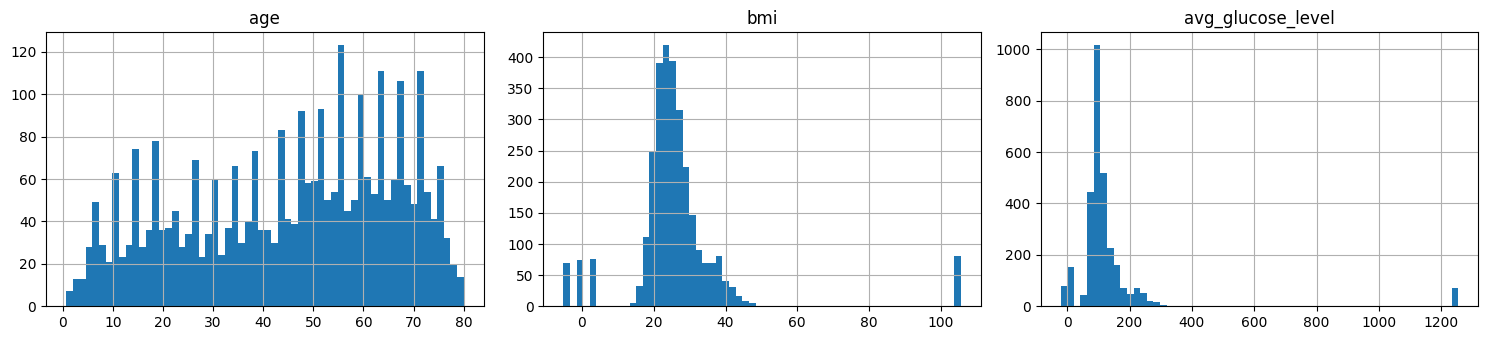

In [11]:
LICZBOWE = ["age", "bmi", "avg_glucose_level"]

display(pacjenci[LICZBOWE].describe().T)
pacjenci[LICZBOWE].hist(bins=60, figsize=(15, 3.5), layout=(1, 3))
plt.tight_layout()
plt.show()

✍️ **Pytanie:** Które wartości minimalne i maksymalne są w ogóle *możliwe* u człowieka?

*Odpowiedź:* wiek - 0,67-80 jest możliwy w całym zakresie; bmi - minimum -5,2 jest niemożliwe, podobnie wartości 0 i 3,4 występujące w danych, natomiast maksimum 105,6 jest nierealne; glukoza - minimum -21,4 jest nierealna, a maksimum 1254,6 jest też nierealny. Wniosek, możliwe są więc tylko minimum i maksimum wieku

## 2.1 Krok 1: wartości niemożliwe

Przyjmujemy progi:

| Zmienna | Zakres możliwy |
|---|---|
| `bmi` | 10–60 |
| `avg_glucose_level` | 20–800 mg/dl |
| `age` | 0–120 lat |

Wartości spoza zakresu to **szum techniczny**, a nie rzadcy pacjenci — zamieniamy je na `NaN`.

1. Utwórz maski `zle_bmi`, `zla_glukoza`, `zly_wiek` (przyda się `Series.between`).
2. Policz, ile wartości jest niemożliwych w każdej kolumnie i ilu pacjentów ma co najmniej jedną taką wartość.
3. Zamień niemożliwe wartości na `NaN`.

In [12]:
zle_bmi = pacjenci["bmi"].notna() & ~pacjenci["bmi"].between(10, 60)
zla_glukoza = pacjenci["avg_glucose_level"].notna() & ~pacjenci["avg_glucose_level"].between(20, 800)
zly_wiek = pacjenci["age"].notna() & ~pacjenci["age"].between(0, 120)

niemozliwa = zle_bmi | zla_glukoza | zly_wiek
print("bmi:", zle_bmi.sum(), "| glukoza:", zla_glukoza.sum(), "| wiek:", zly_wiek.sum())
print("Pacjentów z ≥1 niemożliwą wartością:", niemozliwa.sum())
print(pacjenci.loc[zle_bmi, "bmi"].value_counts())
print(pacjenci.loc[zla_glukoza, "avg_glucose_level"].value_counts())

pacjenci.loc[zle_bmi, "bmi"] = np.nan
pacjenci.loc[zla_glukoza, "avg_glucose_level"] = np.nan
pacjenci.loc[zly_wiek, "age"] = np.nan

bmi: 300 | glukoza: 300 | wiek: 0
Pacjentów z ≥1 niemożliwą wartością: 560
bmi
105.60    80
3.40      76
0.00      74
-5.20     70
Name: count, dtype: int64
avg_glucose_level
-21.40     78
5.00       78
0.00       74
1254.60    70
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
age,3000.00,45.25,20.83,0.67,28.00,49.00,63.00,80.00
bmi,2700.00,26.12,5.84,13.57,21.94,24.98,28.85,47.62
avg_glucose_level,2700.00,116.84,44.45,44.76,89.47,103.09,127.84,332.91


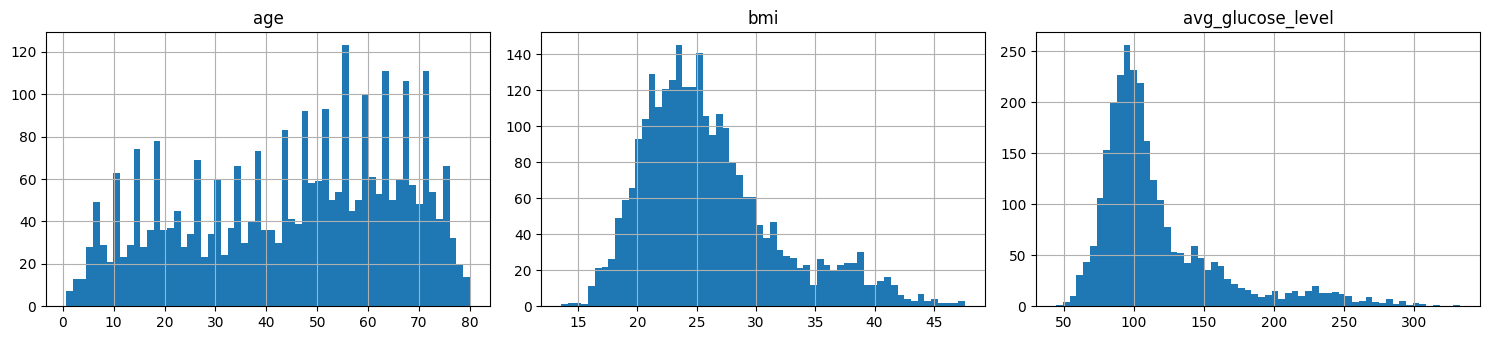

In [13]:
display(pacjenci[LICZBOWE].describe().T)
pacjenci[LICZBOWE].hist(bins=60, figsize=(15, 3.5), layout=(1, 3))
plt.tight_layout()
plt.show()

## 2.2 Krok 2a: wartości skrajne w jednej zmiennej — wykresy

Zanim cokolwiek policzysz, **obejrzyj** dane.

1. Narysuj obok siebie poziome wykresy pudełkowe dla `bmi` i `avg_glucose_level` (`plt.subplots(1, 2)`, `ax.boxplot(..., orientation="horizontal")`). Pamiętaj o `dropna()`.
2. Narysuj obok siebie dwa wykresy punktowe: `age` × `avg_glucose_level` i `age` × `bmi`.

Podpisz osie (z jednostkami) i nadaj tytuły.

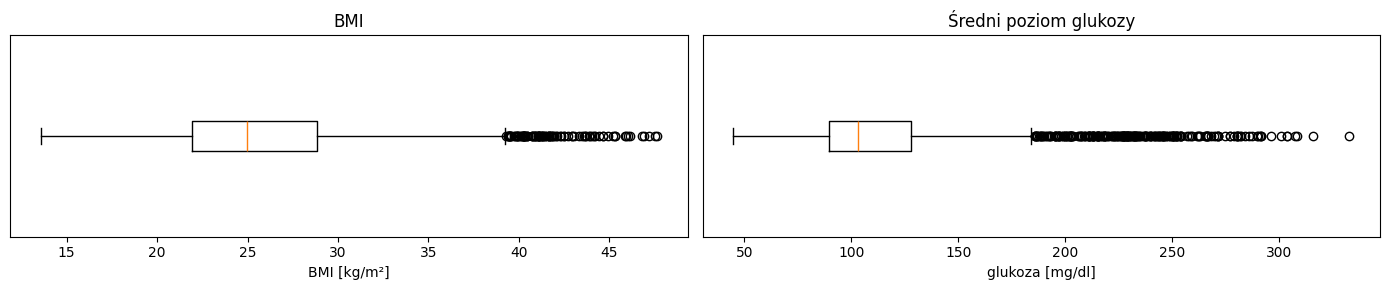

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3))
bp_bmi = axes[0].boxplot(pacjenci["bmi"].dropna(), orientation="horizontal")
axes[0].set(title="BMI", xlabel="BMI [kg/m²]", yticks=[])
bp_glu = axes[1].boxplot(pacjenci["avg_glucose_level"].dropna(), orientation="horizontal")
axes[1].set(title="Średni poziom glukozy", xlabel="glukoza [mg/dl]", yticks=[])
plt.tight_layout()
plt.show()

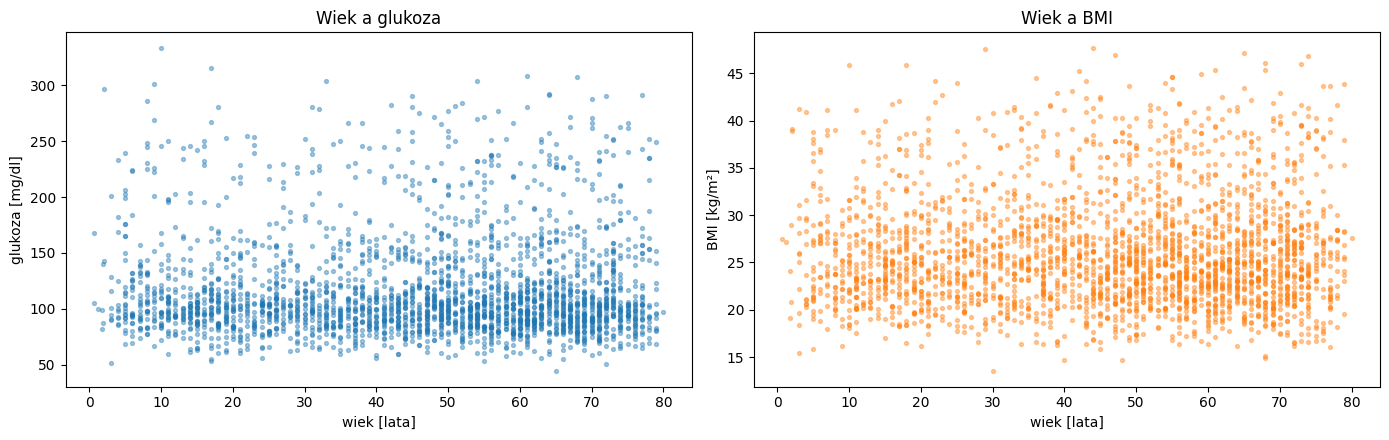

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(pacjenci["age"], pacjenci["avg_glucose_level"], s=8, alpha=0.4)
axes[0].set(title="Wiek a glukoza", xlabel="wiek [lata]", ylabel="glukoza [mg/dl]")
axes[1].scatter(pacjenci["age"], pacjenci["bmi"], s=8, alpha=0.4, color="tab:orange")
axes[1].set(title="Wiek a BMI", xlabel="wiek [lata]", ylabel="BMI [kg/m²]")
plt.tight_layout()
plt.show()

✍️ **Pytania:**
1. Dla której zmiennej jest więcej punktów poza wąsami? Czy leżą po obu stronach pudełka, czy tylko po jednej?
2. Na wykresie punktowym: czy wysokie wartości glukozy występują tylko w określonym wieku? Czy 10-latek ze średnią glukozą ponad 300 mg/dl to błąd, czy rzadki przypadek?

*Odpowiedź:* 1. Więcej punktów poza wąsami ma glukozwa - 235, wobec 100 dla BMI. W obu zmiennych leżą one tylko po prawej stronie pudełka, gdyż oba rozkłady są prawoskośne. 2. Wysoka glukoza występuje w każdym wieku, bez względu na wiek. Dziesięciolatek z glukozą powyżej 300 to rzadki, lecz możliwy przypadek. Nie jest to błąd, więc zostaje on do weryfikacji

## 2.3 Krok 2b: wartości skrajne w jednej zmiennej — metody liczbowe

Napisz trzy funkcje, które dla kolumny `s` zwracają maskę (`True` = wartość odstająca):

- `maska_iqr(s, k=1.5)` — poza $[Q_1 - k \cdot IQR,\; Q_3 + k \cdot IQR]$,
- `maska_z(s, prog=3)` — $|z| > prog$, gdzie $z = (x - \bar{x}) / s$,
- `maska_mad(s, prog=3.5)` — odporny z-score $|0{,}6745 \cdot (x - \text{med}) / \text{MAD}| > prog$.

Braki (`NaN`) nie powinny być oznaczane jako odstające.

In [16]:
def maska_iqr(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

def maska_z(s, prog=3):
    z = (s - s.mean()) / s.std()
    return z.abs() > prog

def maska_mad(s, prog=3.5):
    med = s.median()
    mad = (s - med).abs().median()
    return (0.6745 * (s - med) / mad).abs() > prog

Zbuduj tabelę porównawczą: wiersze = zmienne (`age`, `bmi`, `avg_glucose_level`), kolumny = metody (IQR 1,5, IQR 3, z-score, MAD), wartości = liczba wykrytych obserwacji. Dodaj kolumnę ze **skośnością** (`skew`).

In [17]:
porownanie = pd.DataFrame({
    "IQR 1,5": {c: maska_iqr(pacjenci[c], 1.5).sum() for c in LICZBOWE},
    "IQR 3":   {c: maska_iqr(pacjenci[c], 3).sum()   for c in LICZBOWE},
    "z-score": {c: maska_z(pacjenci[c]).sum()        for c in LICZBOWE},
    "MAD":     {c: maska_mad(pacjenci[c]).sum()      for c in LICZBOWE},
})
porownanie["skośność"] = pacjenci[LICZBOWE].skew()
porownanie

,"IQR 1,5",IQR 3,z-score,MAD,skośność
age,0,0,0,0,-0.33
bmi,100,0,23,33,0.99
avg_glucose_level,235,81,62,223,1.80


✍️ **Pytanie:** Dlaczego dla glukozy metody dają tak różne wyniki, a dla wieku żadna nic nie wykrywa? Spójrz na skośność i histogramy.

*Odpowiedź:* Glukoza jest silnie prawoskośna, ma główny sczyt ok 100 i drugi skok w okolicy 200-250. z-score liczy się ze średniej i odchylenia standardowego które sam ogon zawyża, więc próg ląduje wysoko i metoda wykrywa tylko 62 pkt

### Wykres: zaznacz wartości odstające

Powtórz wykres punktowy `age` × `avg_glucose_level`, ale tym razem:

- zaznacz innym kolorem pacjentów, których glukoza jest odstająca według `maska_iqr` (i podaj ich liczbę w legendzie),
- narysuj poziomą linię przerywaną na górnej granicy $Q_3 + 1{,}5 \cdot IQR$ (`ax.axhline`).

Sprawdź: czy liczba punktów nad linią zgadza się z liczbą punktów poza wąsem na wykresie pudełkowym?

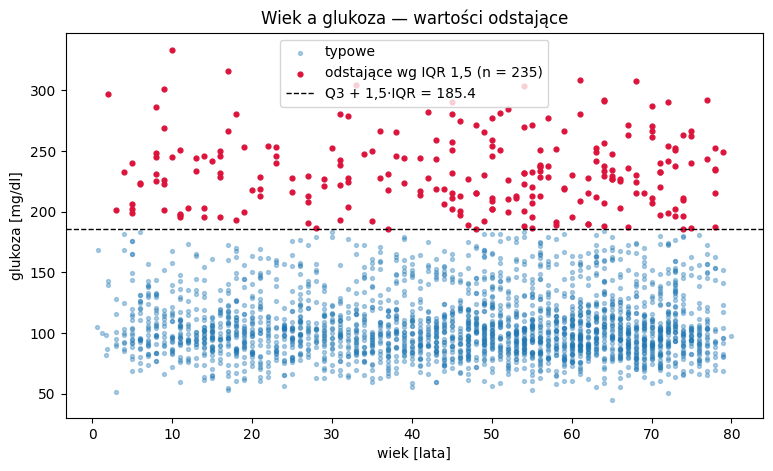

Nad linią: 235 | poza wąsem: 235


In [18]:
g = pacjenci["avg_glucose_level"]
m_glu = maska_iqr(g)
q1, q3 = g.quantile([0.25, 0.75])
gorna = q3 + 1.5 * (q3 - q1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(pacjenci.loc[~m_glu, "age"], g[~m_glu], s=8, alpha=0.35, label="typowe")
ax.scatter(pacjenci.loc[m_glu, "age"], g[m_glu], s=12, color="crimson",
           label=f"odstające wg IQR 1,5 (n = {m_glu.sum()})")
ax.axhline(gorna, ls="--", color="black", lw=1, label=f"Q3 + 1,5·IQR = {gorna:.1f}")
ax.set(title="Wiek a glukoza — wartości odstające", xlabel="wiek [lata]", ylabel="glukoza [mg/dl]")
ax.legend()
plt.show()
print("Nad linią:", (g > gorna).sum(), "| poza wąsem:", len(bp_glu["fliers"][0].get_xdata()))

### Czy wartość odstająca niesie informację?

Wysoki poziom glukozy może być związany z udarem. Porównaj odsetek udarów (`stroke`) wśród pacjentów z glukozą odstającą (IQR 1,5) i wśród pozostałych. Narysuj wykres pudełkowy glukozy w podziale na `stroke`.

,liczba,udary,odsetek
avg_glucose_level,,,
False,2465,520,0.21
True,235,51,0.22


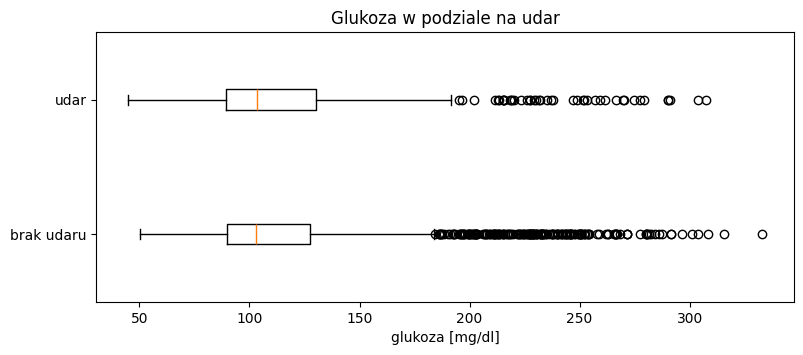

In [19]:
znana = g.notna()
display(pacjenci[znana].groupby(m_glu[znana])["stroke"].agg(liczba="size", udary="sum", odsetek="mean"))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.boxplot([g[(pacjenci["stroke"] == k) & znana] for k in (0, 1)],
           orientation="horizontal", tick_labels=["brak udaru", "udar"])
ax.set(title="Glukoza w podziale na udar", xlabel="glukoza [mg/dl]")
plt.show()

✍️ **Pytanie:** Czy pacjentów z wysoką glukozą należy usunąć z danych, jeśli chcemy przewidywać udar?

*Odpowiedź:* Nie należy ich usuwać. To realne możliwe wartości, a w medycynie wysoka glukoza jest czynnikiem ryzyka udaru, więc usunięcie ucięłoby najważniejszą grupę.

## 2.4 Krok 3: nielogiczne kombinacje kategorii

Każda wartość osobno może być poprawna („dziecko”, „pali”), a niemożliwa jest dopiero ich kombinacja.

1. Zrób tabelę krzyżową `work_type` × `smoking_status` (`pd.crosstab`). Co jest podejrzane?
2. Utwórz maski:
   - `dziecko_pali` — `work_type == "children"` i `smoking_status` to `"smokes"` lub `"formerly smoked"`,
   - `maluch_student` — wiek ≤ 3 lata i `work_type == "student"`.
3. Wyświetl znalezionych pacjentów.

In [20]:
display(pd.crosstab(pacjenci["work_type"], pacjenci["smoking_status"]))

dziecko_pali = (pacjenci["work_type"] == "children") & pacjenci["smoking_status"].isin(["smokes", "formerly smoked"])
maluch_student = (pacjenci["age"] <= 3) & (pacjenci["work_type"] == "student")

print("dziecko_pali:", dziecko_pali.sum(), "| maluch_student:", maluch_student.sum())
display(pacjenci[dziecko_pali | maluch_student].sort_values("age"))

smoking_status,Unknown,formerly smoked,never smoked,smokes
work_type,,,,
Govt_job,16,63,94,67
Never_worked,1,30,36,35
Private,76,440,585,445
Self-employed,18,137,166,131
children,17,0,274,15
student,22,67,190,75


dziecko_pali: 15 | maluch_student: 1


,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
52,A582477,Female,1.80,0,0,False,student,Rural,82.20,24.05,formerly smoked,0
361,A843508,Male,2.00,0,0,False,children,Urban,143.14,39.11,smokes,0
578,A161666,Male,3.00,0,0,False,children,Urban,NaN,15.47,smokes,0
797,A427670,Male,5.00,0,0,False,children,Urban,NaN,19.90,smokes,0
942,A929594,Female,8.00,0,0,False,children,Urban,108.35,19.93,smokes,0
782,A383975,Female,9.00,0,0,False,children,Urban,222.47,25.14,smokes,0
111,A678646,Female,9.00,0,0,False,children,Rural,96.59,22.24,smokes,0
600,A623587,Male,10.00,0,0,False,children,Urban,NaN,20.93,smokes,0
2389,A367897,Male,11.00,0,0,False,children,Urban,NaN,NaN,smokes,0
987,A105353,Male,11.00,0,0,False,children,Urban,59.56,23.02,smokes,0


✍️ **Pytanie:** Czy IQR albo z-score mogłyby wykryć te przypadki? Dlaczego?

*Odpowiedź:* Nie mogłyby. IQR i z-score badają jedną zmienną liczbową, a tu każda wartość osobno jest typowa. Do tego work_type i smoking_status to zmienne kategoryczne, dla których te metody nie mają sensu.

## 2.5 Krok 4: nietypowe kombinacje liczb — odległość od środka

Liczymy kwadrat **odległości euklidesowej** każdego pacjenta od środka danych, po standaryzacji cech:

$$d^2 = \sum_j \left(\frac{x_j - \bar{x}_j}{s_j}\right)^2$$

Dla danych o rozkładzie normalnym $d^2$ ma rozkład $\chi^2$ z $p$ stopniami swobody ($p$ = liczba cech), więc próg bierzemy z kwantyla 0,99.

1. Weź kolumny `LICZBOWE` bez braków (`dropna`) → `X`.
2. Wystandaryzuj je i policz `d2`.
3. Wyznacz próg `chi2.ppf(0.99, df=3)` i policz, ilu pacjentów go przekracza.
4. Sprawdź, **która cecha** ma największy udział w $d^2$ u tych pacjentów (`idxmax(axis=1)` na kwadratach z-score'ów).

In [21]:
from scipy.stats import chi2

X = pacjenci[LICZBOWE].dropna()
Z = (X - X.mean()) / X.std()
d2 = (Z ** 2).sum(axis=1)
prog = chi2.ppf(0.99, df=3)

odlegli = d2 > prog
print(f"N = {len(X)}, próg = {prog:.2f}, odstających: {odlegli.sum()}")
print((Z[odlegli] ** 2).idxmax(axis=1).value_counts())

N = 2440, próg = 11.34, odstających: 73
avg_glucose_level    54
bmi                  19
Name: count, dtype: int64


Glukoza jest silnie prawoskośna, więc odległość wskazuje głównie jej długi ogon. Powtórz obliczenia po zlogarytmowaniu glukozy (`np.log`) i porównaj liczbę odstających. Narysuj wykres punktowy `bmi` × `avg_glucose_level`, zaznaczając pacjentów odstających po transformacji.

Przed log: 73 | po log: 31
                   age   bmi  avg_glucose_level
age               1.00  0.02               0.01
bmi               0.02  1.00              -0.02
avg_glucose_level 0.01 -0.02               1.00


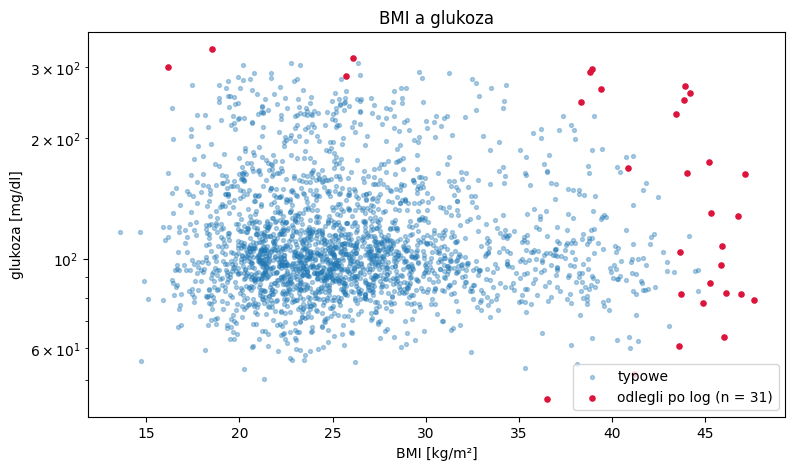

In [22]:
X_log = X.copy()
X_log["avg_glucose_level"] = np.log(X_log["avg_glucose_level"])
Z_log = (X_log - X_log.mean()) / X_log.std()
d2_log = (Z_log ** 2).sum(axis=1)
odlegli_log = d2_log > prog

print("Przed log:", odlegli.sum(), "| po log:", odlegli_log.sum())
print(X.corr().round(3))

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(X.loc[~odlegli_log, "bmi"], X.loc[~odlegli_log, "avg_glucose_level"], s=8, alpha=0.35, label="typowe")
ax.scatter(X.loc[odlegli_log, "bmi"], X.loc[odlegli_log, "avg_glucose_level"], s=14, color="crimson",
           label=f"odlegli po log (n = {odlegli_log.sum()})")
ax.set(title="BMI a glukoza", xlabel="BMI [kg/m²]", ylabel="glukoza [mg/dl]", yscale="log")
ax.legend()
plt.show()

✍️ **Pytanie:** Wiek, BMI i glukoza są tu prawie nieskorelowane (sprawdź `X.corr()`). Czy w takiej sytuacji odległość Mahalanobisa dałaby coś więcej niż euklidesowa?

*Odpowiedź:* Praktycznie nie. Korelacje między cechami mają |r|<= 0,02, więc macierz kowariancji jest prawie diagonalny. Wtedy odległość Mahalanobisa sprowadza się do sumy kwadratów z-scoreów, czyli do policzonej tu odległości euklidesowej po standaryzacji. Mahalanobis daje przewagę dopiero przy sorelowanych cechach.

### Dla chętnych: Isolation Forest

Użyj `sklearn.ensemble.IsolationForest` (`contamination=0.01`, `random_state=0`) na `X_log`. Ilu pacjentów wskazuje jednocześnie Isolation Forest i odległość `d2_log`?

In [23]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.01, random_state=0)
iso_flaga = pd.Series(iso.fit_predict(X_log) == -1, index=X_log.index)
print("IF:", iso_flaga.sum(), "| d2_log:", odlegli_log.sum(), "| wspólnie:", (iso_flaga & odlegli_log).sum())

IF: 25 | d2_log: 31 | wspólnie: 19


## 2.6 Krok 5: podsumowanie i decyzja

Zbierz wyniki wszystkich kroków w jednej ramce `flagi` (jeden wiersz na pacjenta, indeks jak w `oryginal`) z kolumnami logicznymi:

- `niemozliwa_wartosc` (krok 1),
- `glukoza_iqr` (krok 2, IQR 1,5 dla glukozy),
- `nielogiczna_kategoria` (krok 3),
- `odlegly_od_srodka` (krok 4, `d2_log`; pacjenci bez obliczonej odległości → `False`).

Policz, ilu pacjentów ma każdą flagę i ilu ma co najmniej jedną.

In [24]:
flagi = pd.DataFrame({
    "niemozliwa_wartosc": niemozliwa,
    "glukoza_iqr": maska_iqr(pacjenci["avg_glucose_level"]),
    "nielogiczna_kategoria": dziecko_pali | maluch_student,
    "odlegly_od_srodka": odlegli_log.reindex(oryginal.index, fill_value=False),
}, index=oryginal.index)

print(flagi.sum())
print("Co najmniej jedna flaga:", flagi.any(axis=1).sum())

niemozliwa_wartosc       560
glukoza_iqr              235
nielogiczna_kategoria     16
odlegly_od_srodka         31
dtype: int64
Co najmniej jedna flaga: 806


✍️ **Decyzja:** dla każdej grupy zaproponuj strategię i uzasadnij ją jednym zdaniem.

| Grupa | Strategia (poprawić / NaN / usunąć / przyciąć / log / zostawić / flaga) | Uzasadnienie |
|---|---|---|
| wartości niemożliwe | NaN (+flaga) | To techniczne kody błędów a nie pomiary, ale pozostałe kolumny tych pacjentów są wartościowe, więc nie usuwamy całych wierszy |
| wysoka glukoza (IQR) | zostawić+log | To prawdziwe wartości z ogona rozkładu potencjalne związane z udarem, więc usunięcie lub przycięcie zniekształciłoby dane |
| nielogiczne kategorie | poprawić (+flaga) | Wiek jest wiarygodny, a błędna jest kategoria, więc u dzieci ustawiamy never smoked, a u 1,8-latka children |
| odlegli od środka | zostawić+flaga | Każda wartość osobno jest możliwa, a rzadka kombinacja to powód do weryfikacji, nie do usuwania. |